<a href="https://colab.research.google.com/github/speediedan/finetuning-scheduler/blob/main/src/fts_examples/notebooks/publish/tunable_views/lora_placement_lightning.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" />
</a>

# Where Should LoRA Go? The Lightning API Companion

This is the Lightning API version of [Where Should LoRA Go? Probing *LoRA Without Regret* with
Addresses](lora_placement.ipynb), which runs the experiment on Fine-Tuning Scheduler's PyTorch API. It runs the same
five conditions over the same model, data, initialization, training budget and evaluation, with the
`FinetuningScheduler` callback and a Lightning `Trainer` in place of the plain PyTorch loop. Three things change, and
this notebook shows each:

1. **the view is rooted at the `LightningModule`**: `venngram.view(module)` reports the same roles, layers and
   components as the PyTorch notebook's view of the bare model, and its physical names gain the module's `model.`
   prefix. Before any training, the notebook checks that every condition selects exactly the PyTorch notebook's
   tensors, under that prefix;
2. **transitions are by epoch**: the Lightning callback has no step-based transition (`max_transition_step` belongs to
   the PyTorch API), so the run is two epochs of `MAX_STEPS // 2` steps over the PyTorch notebook's exact batch
   sequence, and "MLP, then attention" adds the attention adapters at the epoch boundary, after the same optimizer
   step as the PyTorch run;
3. **the callback is configured as the plain loop behaves**: no restore of the best checkpoint at a transition
   (`restore_best=False`), a new phase's tensors at the same learning rate (`base_max_lr=LR`), and transitions by
   epoch alone rather than by early stopping (`epoch_transitions_only=True`).

The experiment is the PyTorch notebook's, so its framing holds here too. [LoRA Without
Regret](https://thinkingmachines.ai/blog/lora/) (Schulman and Thinking Machines Lab, September 2025) reports that LoRA
on the MLP layers matches full fine-tuning on small and medium supervised datasets, that adding attention adapters on
top gains nothing, and that attention-only LoRA falls behind. This is a probe of that 2025 result, not a replication
and not a new 2026 study: a 0.6B model, a slice of GSM8K, a few hundred steps, one seed. Treat the result as a
hypothesis check.

## Setup

The parameters below are the PyTorch notebook's, with the same values (the docs render uses them as given; the tests
shorten them). `MAX_STEPS` must be even and `MAX_STEPS // 2` a multiple of `EVAL_EVERY`, so that the transition and
every evaluation fall where the PyTorch run puts them.

In [2]:
MODEL_ID = "Qwen/Qwen3-0.6B"
RANK = 16
ALPHA = 32
LR = 2e-4  # LoRA's best rate is about 10x full fine-tuning's (LoRA Without Regret); 2e-5 is a typical full rate here
MAX_STEPS = 300
EVAL_EVERY = 25
BATCH_SIZE = 8
SEQ_LEN = 256
N_TRAIN = 2400
N_EVAL = 256
SEED = 42

In [3]:
import copy
import logging
import random
import tempfile
import time
import warnings

import datasets
import lightning as L
import matplotlib.pyplot as plt
import torch
import transformers
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer

from finetuning_scheduler import FinetuningScheduler, FTSCheckpoint
from finetuning_scheduler.core.compile import compile_schedule
from finetuning_scheduler.testing import TunableViewConformance
import venngram

from fts_examples.tunable_views import use_seed_registry
from fts_examples.tunable_views.lora import add_lora

warnings.filterwarnings("ignore", message=".*addresses.*experimental")  # said once per process; we know
# each condition is its own Trainer run: keep Lightning's and the callback's per-run notices out of the output
# (the callback sets the rank-zero logger's level itself, from its `logging_level` argument)
for logger in ("lightning.pytorch", "lightning.fabric"):
    logging.getLogger(logger).setLevel(logging.ERROR)
for notice in (".*optional dependency of finetuning-scheduler", ".*does not have many workers", ".*will be overidden by",
               ".*LeafSpec"):
    warnings.filterwarnings("ignore", message=notice)
print("component maps from:", *use_seed_registry())
datasets.disable_progress_bars()
transformers.utils.logging.disable_progress_bar()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.bfloat16 if device.type == "cuda" else torch.float32
print(f"device: {device}, dtype: {dtype}")

component maps from: hub-dataset:speediedan/venngram-registry/index@d927d8736e4b2681a1f4291784ef697a53710b2a
device: cuda, dtype: torch.bfloat16


## The Data

The PyTorch notebook's data: grade-school math word problems with worked answers
([GSM8K](https://huggingface.co/datasets/openai/gsm8k)) as `Question: ... Answer: ...` text, next-token cross-entropy
over the whole sequence, and a fixed slice of the test split for evaluation.

The PyTorch loop draws its batches from one shuffled pass over the training set after another, each pass seeded with
`SEED` plus the step it starts at. `step_batches()` replays that order and cuts it at `MAX_STEPS`, and each epoch of
the Lightning run takes its half of the sequence, so both runs see the same batches in the same order.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
gsm8k = load_dataset("openai/gsm8k", "main")


def encode(split, n):
    texts = [f"Question: {r['question']}\nAnswer: {r['answer']}{tokenizer.eos_token}" for r in gsm8k[split].select(range(n))]
    return tokenizer(texts, truncation=True, max_length=SEQ_LEN, padding="max_length", return_tensors="pt")


train_data, eval_data = encode("train", N_TRAIN), encode("test", N_EVAL)


def batch(data, idx):
    ids, mask = data["input_ids"][idx], data["attention_mask"][idx]
    return ids, mask, ids.masked_fill(mask == 0, -100)


def step_batches():
    """The PyTorch notebook's batch order: shuffled passes, each seeded with ``SEED`` plus its first step."""
    order, step, n = [], 0, train_data["input_ids"].shape[0]
    while step < MAX_STEPS:
        idx = list(range(n))
        random.Random(SEED + step).shuffle(idx)
        for i in range(0, n - BATCH_SIZE + 1, BATCH_SIZE):
            order.append(idx[i:i + BATCH_SIZE])
            step += 1
            if step == MAX_STEPS:
                break
    return order


EPOCHS = 2
assert MAX_STEPS % EPOCHS == 0 and (MAX_STEPS // EPOCHS) % EVAL_EVERY == 0, "see the Setup section"
STEPS_PER_EPOCH = MAX_STEPS // EPOCHS
TRAIN_BATCHES = [batch(train_data, idx) for idx in step_batches()]
n_eval = eval_data["input_ids"].shape[0]
EVAL_BATCHES = [batch(eval_data, list(range(i, i + BATCH_SIZE))) for i in range(0, n_eval - BATCH_SIZE + 1, BATCH_SIZE)]
print(f"{len(TRAIN_BATCHES)} training batches ({EPOCHS} epochs of {STEPS_PER_EPOCH}) and {len(EVAL_BATCHES)} "
      f"evaluation batches of {BATCH_SIZE} sequences of {SEQ_LEN} tokens")

300 training batches (2 epochs of 150) and 32 evaluation batches of 8 sequences of 256 tokens


## The Model, the Module and the View

The base model is the PyTorch notebook's: Qwen3-0.6B with a `LoRALinear` on each of its seven projections (the frozen
base layer plus $\frac{\alpha}{r} B A x$, with $B$ initialized to zero), loaded once, so that every condition starts
from a copy of the same weights and the same adapters.

`PlacementModule` is the `LightningModule` around it. It holds the model as `model`, trains on the epoch's half of the
batch sequence, logs the evaluation loss as `val_loss`, and builds its optimizer over the tensors the callback has
thawed: AdamW at `LR` with no weight decay, as in the PyTorch notebook.

The view is rooted at the module rather than at the model, and attached to it as `tunable_view`, which is where the
callback looks for it. `venngram.view(module)` finds the model's component map and the adapters' map just as
`venngram.view(model)` does, so every tensor keeps its role, layer and component, and only its physical name changes:
it now carries the module's `model.` prefix.

In [5]:
class PlacementModule(L.LightningModule):
    """The LoRA'd model, trained an epoch at a time on the PyTorch notebook's batch sequence."""

    def __init__(self, model):
        super().__init__()
        self.model = model
        self.curve = []

    def forward(self, ids, mask, labels):
        return self.model(input_ids=ids, attention_mask=mask, labels=labels).loss

    def training_step(self, batch, batch_idx):
        return self(*batch)

    def validation_step(self, batch, batch_idx):
        self.log("val_loss", self(*batch), batch_size=batch[0].shape[0])

    def on_validation_epoch_end(self):
        self.curve.append((self.global_step, self.trainer.callback_metrics["val_loss"].item()))

    def configure_optimizers(self):
        # the callback thaws phase 0 before this runs, and adds each later phase's tensors at `base_max_lr`
        return torch.optim.AdamW([p for p in self.parameters() if p.requires_grad], lr=LR, weight_decay=0.0)

    def train_dataloader(self):
        start = self.trainer.current_epoch * STEPS_PER_EPOCH
        return DataLoader(TRAIN_BATCHES[start:start + STEPS_PER_EPOCH], batch_size=None)

    def val_dataloader(self):
        return DataLoader(EVAL_BATCHES, batch_size=None)


torch.manual_seed(SEED)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device)
TARGETS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")
add_lora(base, TARGETS, r=RANK, alpha=ALPHA)
base.requires_grad_(False)

view = venngram.view(PlacementModule(base))
structure = view.structure()
for name in ("model.model.layers.27.self_attn.q_proj.lora_A.weight", "model.model.layers.27.mlp.down_proj.base.weight",
             "model.model.layers.0.post_attention_layernorm.weight", "model.model.embed_tokens.weight"):
    print(f"{name:<58} role={view.roles().get(name, 'base'):<8} {structure.locate(name)}")

model.model.layers.27.self_attn.q_proj.lora_A.weight       role=adapter  Location(stack=None, layer=27, component='attn.q')
model.model.layers.27.mlp.down_proj.base.weight            role=base     Location(stack=None, layer=27, component='mlp.out')
model.model.layers.0.post_attention_layernorm.weight       role=base     Location(stack=None, layer=0, component='ln2')
model.model.embed_tokens.weight                            role=base     Location(stack=None, layer=None, component='embed')


## Checking the View

`TunableViewConformance` runs every case of the protocol and every case Fine-Tuning Scheduler relies on: compiling a
schedule, thawing, an optimizer step and the refusals. Its factory builds a fresh module around a copy of the model,
because the cases change the model.

In [6]:
report = TunableViewConformance(lambda: venngram.view(PlacementModule(copy.deepcopy(base)))).run()
print("conformance:", "ok" if report.ok else report.failures)

conformance: ok


## The Conditions, as the Callback Runs Them

`CONDITIONS` is the PyTorch notebook's dictionary, unchanged: the same five schedules, with the phased condition's
transition at step `MAX_STEPS // 2`. `for_lightning` restates each one for the callback without changing what it
selects:

- a `max_transition_step` becomes the `max_transition_epoch` that ends at that step, and is refused unless the step
  falls on an epoch boundary;
- with `epoch_transitions_only`, every phase needs a `max_transition_epoch`, so the last phase is given the run's last
  epoch.

| condition | phase 0 | phase 1 (from step `MAX_STEPS // 2`, the second epoch) |
| --- | --- | --- |
| attention only | `role:adapter & component:attn.*` | |
| MLP only | `role:adapter & component:mlp.*` | |
| all layers | `role:adapter` | |
| MLP + norms | `role:adapter & component:mlp.*`, `role:base & (component:ln1 \| component:ln2)` | |
| MLP, then attention | `role:adapter & component:mlp.*` | `role:adapter & component:attn.*` |

The check below is the point of this section. Each condition is compiled twice: as the callback runs it, over the
view rooted at the module, and as the PyTorch notebook runs it, over a view of the bare model. Phase by phase, the two
must select the same tensors, the module's names being the model's with the `model.` prefix.

In [7]:
CONDITIONS = {
    "attention only": {0: {"params": ["role:adapter & component:attn.*"]}},
    "MLP only": {0: {"params": ["role:adapter & component:mlp.*"]}},
    "all layers": {0: {"params": ["role:adapter"]}},
    "MLP + norms": {0: {"params": ["role:adapter & component:mlp.*", "role:base & (component:ln1 | component:ln2)"]}},
    "MLP, then attention": {0: {"params": ["role:adapter & component:mlp.*"], "max_transition_step": MAX_STEPS // 2},
                            1: {"params": ["role:adapter & component:attn.*"]}},
}


def for_lightning(schedule):
    """A PyTorch API schedule as the callback runs it: each step transition at the epoch it ends, the last phase at
    the run's end."""
    restated = {}
    for depth, phase in schedule.items():
        phase = dict(phase)
        step = phase.pop("max_transition_step", None)
        if step is None:
            assert depth == max(schedule), "only the last phase may run to the end"
            phase["max_transition_epoch"] = EPOCHS
        else:
            assert step % STEPS_PER_EPOCH == 0, f"step {step} is not an epoch boundary"
            phase["max_transition_epoch"] = step // STEPS_PER_EPOCH
        restated[depth] = phase
    return restated


def selections(schedule, view, prefix=""):
    return [sorted(prefix + n for n in phase.physical) for phase in compile_schedule(schedule, view).phases]


params = dict(base.named_parameters())
model_view = venngram.view(base)  # the PyTorch notebook's view, rooted at the Hugging Face model
trainable = {}
for name, schedule in CONDITIONS.items():
    lightning = selections(for_lightning(schedule), view)
    pytorch = selections(schedule, model_view)
    assert lightning == selections(schedule, model_view, prefix="model."), name
    trainable[name] = sum(params[n].numel() for phase in pytorch for n in phase)
    print(f"{name:<20} {sum(map(len, lightning)):>4} tensors in {len(lightning)} phase(s), "
          f"{trainable[name] / 1e6:6.2f}M trainable parameters: selects the PyTorch notebook's tensors")

attention only        224 tensors in 1 phase(s),   4.59M trainable parameters: selects the PyTorch notebook's tensors


MLP only              168 tensors in 1 phase(s),   5.51M trainable parameters: selects the PyTorch notebook's tensors
all layers            392 tensors in 1 phase(s),  10.09M trainable parameters: selects the PyTorch notebook's tensors


MLP + norms           224 tensors in 1 phase(s),   5.56M trainable parameters: selects the PyTorch notebook's tensors


MLP, then attention   392 tensors in 2 phase(s),  10.09M trainable parameters: selects the PyTorch notebook's tensors


## Training

Each condition runs on a fresh module around a copy of the base model, with its own `Trainer`. Besides the three
callback settings above:

- `val_check_interval=EVAL_EVERY` evaluates every `EVAL_EVERY` optimizer steps, and the step-0 evaluation is taken
  before `fit`, as the PyTorch loop takes it before its first step;
- `FTSCheckpoint(monitor="val_loss", save_top_k=0)` gives the callback the checkpoint callback it requires without
  writing a checkpoint, since nothing is restored;
- the precision is Lightning's default, which leaves the model in the dtype it was loaded in, as the PyTorch loop
  does.

Every run records its wall time and, on a GPU, its peak memory.

In [8]:
@torch.no_grad()
def evaluate(model):
    model.eval()
    losses = [model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device)).loss.item()
              for ids, mask, labels in EVAL_BATCHES]
    model.train()
    return sum(losses) / len(losses)


run_dir = tempfile.mkdtemp(prefix="lora_placement_lightning_")


def train(schedule):
    module = PlacementModule(copy.deepcopy(base))
    module.tunable_view = venngram.view(module)
    module.curve.append((0, evaluate(module.model)))
    callbacks = [FinetuningScheduler(ft_schedule=for_lightning(schedule), base_max_lr=LR, restore_best=False,
                                     epoch_transitions_only=True, logging_level=logging.ERROR),
                 FTSCheckpoint(monitor="val_loss", save_top_k=0)]
    trainer = L.Trainer(max_epochs=EPOCHS, val_check_interval=EVAL_EVERY, num_sanity_val_steps=0,
                        reload_dataloaders_every_n_epochs=1, callbacks=callbacks, accelerator=device.type, devices=1,
                        logger=False, enable_progress_bar=False, enable_model_summary=False, default_root_dir=run_dir)
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.fit(module)
    cost = {"seconds": time.perf_counter() - start,
            "peak_gib": torch.cuda.max_memory_allocated() / 2**30 if device.type == "cuda" else float("nan")}
    assert trainer.global_step == MAX_STEPS, trainer.global_step
    curve = module.curve
    del module, trainer
    torch.cuda.empty_cache() if device.type == "cuda" else None
    return curve, cost


results, costs = {}, {}
for name, schedule in CONDITIONS.items():
    results[name], costs[name] = train(schedule)
    print(f"{name:<20} eval loss {results[name][0][1]:.4f} -> {results[name][-1][1]:.4f}")

attention only       eval loss 1.7620 -> 1.0432


MLP only             eval loss 1.7620 -> 1.0322


all layers           eval loss 1.7620 -> 1.0276


MLP + norms          eval loss 1.7620 -> 1.0332


MLP, then attention  eval loss 1.7620 -> 1.0303


## Results

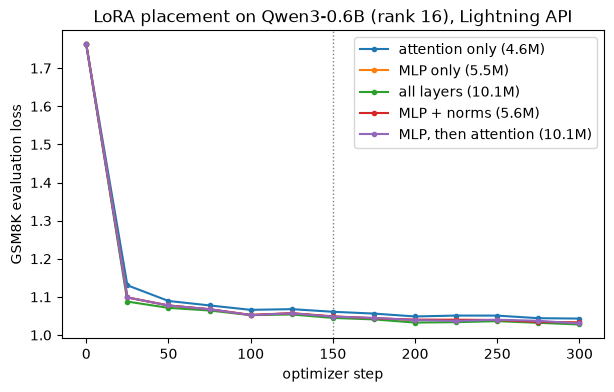

all layers           final eval loss 1.0276 (+0.0000 vs best),  123.8 s, peak memory 11.05 GiB
MLP, then attention  final eval loss 1.0303 (+0.0026 vs best),  115.2 s, peak memory 11.05 GiB
MLP only             final eval loss 1.0322 (+0.0045 vs best),  100.4 s, peak memory 9.85 GiB
MLP + norms          final eval loss 1.0332 (+0.0055 vs best),  137.9 s, peak memory 10.13 GiB
attention only       final eval loss 1.0432 (+0.0156 vs best),  102.8 s, peak memory 9.91 GiB


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, curve in results.items():
    steps, losses = zip(*curve)
    ax.plot(steps, losses, marker="o", markersize=3, label=f"{name} ({trainable[name] / 1e6:.1f}M)")
ax.axvline(MAX_STEPS // 2, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("optimizer step")
ax.set_ylabel("GSM8K evaluation loss")
ax.set_title(f"LoRA placement on {MODEL_ID.split('/')[-1]} (rank {RANK}), Lightning API")
ax.legend()
plt.show()

best = min(results, key=lambda n: results[n][-1][1])
for name, curve in sorted(results.items(), key=lambda kv: kv[1][-1][1]):
    print(f"{name:<20} final eval loss {curve[-1][1]:.4f} ({curve[-1][1] - results[best][-1][1]:+.4f} vs best), "
          f"{costs[name]['seconds']:6.1f} s, peak memory {costs[name]['peak_gib']:.2f} GiB")

## What This Shows

In the docs render of this notebook (300 steps, one seed, on one RTX 4090), the Lightning run reproduces the PyTorch
notebook's run. Every condition finishes at the PyTorch render's final evaluation loss to four decimals: all layers
1.0276, MLP then attention 1.0303, MLP only 1.0322, MLP + norms 1.0332, attention only 1.0432. So the placement
result and its caveats are the PyTorch notebook's, and [its discussion](lora_placement.ipynb) applies here unchanged:
attention-only LoRA lags at a near-matched parameter count, MLP-only LoRA comes close to all-layer LoRA, training the
norms adds nothing, and phasing costs little.

What this notebook adds is the evidence that the two APIs ran the same experiment:

- **The selections are the same.** Rooted at the `LightningModule`, the view gave every tensor the role, layer and
  component the model's own view gives it, and every condition selected the PyTorch notebook's tensors phase by
  phase, checked before any training rather than inferred from the losses.
- **The transition is the same.** "MLP, then attention" crossed to its second phase after step 150 in both runs: at a
  step in the PyTorch loop, at the epoch boundary here, over the same batch sequence.
- **The callback's settings matter.** With its defaults, the transition would restore the best checkpoint of the first
  phase and add the attention adapters at `base_max_lr`'s default of `1e-5` rather than `LR`, so the phased condition
  would be a different experiment. Matching the plain loop took three arguments.

Equal to four decimals on one GPU and software stack is strong agreement, not a promise of bitwise equality: other
hardware or library versions can move the last digits. Each condition took about two minutes here, at a peak of 10 to
11 GiB of GPU memory, as the cost line under each result reports.

## Doing This with Your Own LightningModule

- Root the view at the module and attach it as `tunable_view`: `module.tunable_view = venngram.view(module)`. The
  view finds the model inside the module, so the same addresses select the same tensors, whatever attribute holds the
  model. If venngram has no map for the architecture, Fine-Tuning Scheduler's `tunable-view-generator` agent skill
  drafts and verifies one.
- Check the view with `TunableViewConformance` before training, as here, with a factory that builds a fresh module.
- Write transitions in epochs. A step-based transition is a PyTorch API feature: either size the epochs so that the
  transition falls on a boundary, as this notebook does, or run the schedule on the PyTorch API, as
  [the PyTorch notebook](lora_placement.ipynb) does.
- Decide what the callback should do at a transition. Its defaults (restoring the best checkpoint, a new phase's
  tensors at `base_max_lr`, transitions by early stopping) suit scheduled fine-tuning; a controlled comparison like
  this one sets them to match the run it is compared with.
- Compile the schedule against the view before a long run (`compile_schedule(schedule, view)`) to see exactly which
  tensors each phase will thaw.

[Addressing Across Architectures](cross_architecture_addresses.ipynb) compiles these conditions, unchanged, on four
model families side by side, without training.